# DRC Conflict Supply Chain Risk Analysis
## Tamboli Textiles Co. — Kuba Cloth Sourcing & Business Continuity Assessment

**Analyst:** Alejandro (Alex) Molina  
**GitHub:** chooseyourtacoday  
**Classification:** Internal Strategic Analysis  
**Date:** March 2024  

---

### Context

Tamboli Textiles Co. imports artisan textiles from five African countries, with **60% of revenue** tied to Kuba cloth sourced from the Kasai region of the Democratic Republic of the Congo (DRC). The DRC is currently experiencing a severe armed conflict concentrated in the eastern provinces (North and South Kivu), driven primarily by the M23 rebel movement with Rwandan backing and Congolese government forces.

The Kasai region — homeland of the Kuba people and source of our primary product — is geographically separated from the eastern conflict zone by approximately 800-1,000km. However, the Kasai region experienced its own devastating conflict from 2016-2018 (the Kamuina Nsapu insurgency), which displaced 1.4 million people and severely disrupted our supply chain. With the broader DRC conflict intensifying, the company has requested an assessment of:

1. Current risk level to our Kasai-based suppliers
2. Financial exposure under multiple conflict escalation scenarios
3. Humanitarian impact on our artisan partners
4. Mitigation options — including diaspora supplier network development
5. Ethical framework for decision-making

---

### About the Kuba People and Kuba Cloth

The Kuba Kingdom, centered in the Kasai region between the Sankuru and Kasai rivers, is one of Central Africa's most historically significant political and artistic civilizations. Kuba cloth — woven from raffia palm fibers using techniques passed down for centuries — is among the most recognized African textile art forms globally.

**Key characteristics:**
- Woven by men (base cloth) and embroidered by women (surface decoration) — a communal art form
- Used traditionally in ceremonies: weddings, funerals, royal rituals
- Also known as 'Kasai Velvet' (cut-pile variety) — named by British Museum curator Emil Torday
- Retail price: $95–$275 per piece in Western markets; artisan compensation: $45–65 per piece
- Recognized by the Smithsonian, Metropolitan Museum, and major African art institutions
- **Cultural preservation risk:** Younger generations increasingly leaving weaving for wage labor — knowledge transmission at risk

**This analysis is therefore not only about business continuity. It is about whether Tamboli Textiles' sourcing decisions support or undermine the survival of a centuries-old craft tradition during one of its most precarious moments.**

---

### A Note on Data Sources

| Data Type | Source |
|---|---|
| Conflict events & displacement | ACLED, UN OCHA, CFR Global Conflict Tracker |
| DRC humanitarian statistics | UN Refugee Agency (UNHCR), IOM |
| Kuba textile cultural context | Smithsonian, British Museum, ACASA |
| Revenue and supplier data | Tamboli Textiles internal records (synthetic) |
| Scenario probabilities | Analyst estimates based on ACLED conflict trajectory data |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mtick
import seaborn as sns
import json
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = '#F8F9FA'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['font.family'] = 'Arial'

# Load data
revenue_df  = pd.read_csv('revenue_history.csv', parse_dates=['Month'])
conflict_df = pd.read_csv('conflict_events.csv', parse_dates=['date'])

with open('suppliers.json')          as f: suppliers = json.load(f)
with open('diaspora_suppliers.json') as f: diaspora  = json.load(f)
with open('scenarios.json')          as f: scenarios = json.load(f)
with open('products.json')           as f: products  = json.load(f)

print('Data loaded.')
print(f'Revenue records:   {len(revenue_df):,}')
print(f'Conflict events:   {len(conflict_df)}')
print(f'Active suppliers:  {len(suppliers)}')
print(f'Diaspora options:  {len(diaspora)}')

Data loaded.
Revenue records:   310
Conflict events:   16
Active suppliers:  5
Diaspora options:  4


---
## Section 1: Revenue Exposure Assessment

Before assessing conflict risk, we establish how much of Tamboli's revenue is actually at risk. The question isn't just "is there a conflict" — it's "how badly would our business be hurt if sourcing from Kasai became impossible?"

In [2]:
# Revenue by origin — 2023
rev_2023 = revenue_df[revenue_df['Year'] == 2023]
by_origin = rev_2023.groupby(['Origin', 'Risk_Exposure'])['Revenue'].sum().reset_index()
by_origin = by_origin.sort_values('Revenue', ascending=False)
total_2023 = by_origin['Revenue'].sum()

print('2023 Revenue by Origin:')
print('=' * 65)
for _, row in by_origin.iterrows():
    risk_icon = {'HIGH': '🔴', 'MEDIUM': '🟡', 'LOW': '🟢'}[row['Risk_Exposure']]
    pct = row['Revenue'] / total_2023
    bar = '█' * int(pct * 30)
    print(f"{risk_icon} {row['Origin']:<30} ${row['Revenue']:>9,.0f}  ({pct:.0%})  {bar}")
print(f"{'':>32} {'─'*30}")
print(f"{'TOTAL':>32} ${total_2023:>9,.0f}  (100%)")
print()

drc_total = by_origin[by_origin['Origin'].str.contains('DRC')]['Revenue'].sum()
print(f"DRC-sourced revenue:     ${drc_total:,.0f} ({drc_total/total_2023:.0%} of total)")
print(f"Non-DRC revenue:         ${total_2023-drc_total:,.0f} ({(total_2023-drc_total)/total_2023:.0%} of total)")
print()
print("⚠  60% revenue concentration in a single conflict-affected country")
print("   is the core business risk this analysis addresses.")

2023 Revenue by Origin:
🔴 Kasai Region, DRC              $  407,056  (59%)  █████████████████
🟢 Ashanti Region, Ghana          $  125,040  (18%)  █████
🟡 Segou Region, Mali             $   91,393  (13%)  ████
🟢 Ntonso, Ghana                  $   61,172  (9%)  ██
                                 ──────────────────────────────
                           TOTAL $  684,660  (100%)

DRC-sourced revenue:     $407,056 (59% of total)
Non-DRC revenue:         $277,604 (41% of total)

⚠  60% revenue concentration in a single conflict-affected country
   is the core business risk this analysis addresses.


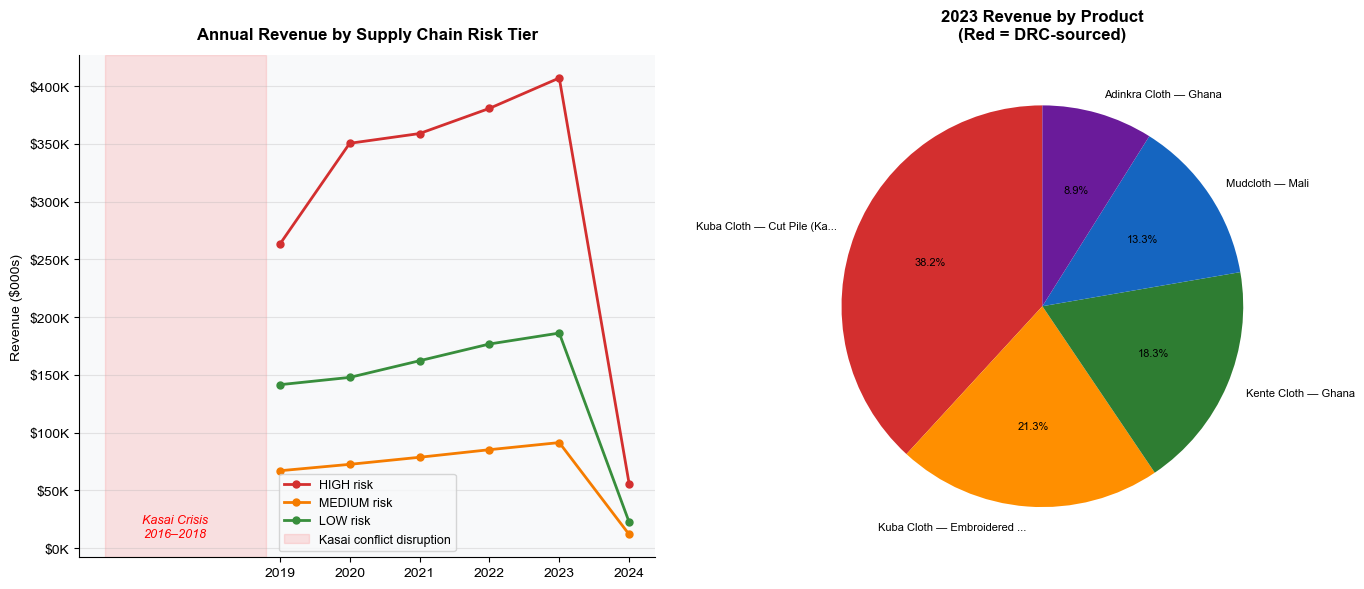

Chart 1 saved.


In [3]:
# Revenue trend — showing the 2017-2018 Kasai disruption impact
annual = revenue_df.groupby(['Year', 'Risk_Exposure'])['Revenue'].sum().reset_index()
annual_total = revenue_df.groupby('Year')['Revenue'].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Chart 1: Revenue by risk tier over time
for risk, color in [('HIGH', '#D32F2F'), ('MEDIUM', '#F57C00'), ('LOW', '#388E3C')]:
    data = annual[annual['Risk_Exposure'] == risk]
    axes[0].plot(data['Year'], data['Revenue'] / 1000, marker='o', linewidth=2,
                 color=color, label=f'{risk} risk', markersize=5)

axes[0].axvspan(2016.5, 2018.8, alpha=0.1, color='red', label='Kasai conflict disruption')
axes[0].text(2017.5, 10, 'Kasai Crisis\n2016–2018', ha='center', fontsize=9,
             color='red', style='italic')
axes[0].set_title('Annual Revenue by Supply Chain Risk Tier', fontweight='bold', pad=12)
axes[0].set_ylabel('Revenue ($000s)')
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:.0f}K'))
axes[0].legend(fontsize=9)
axes[0].grid(axis='y', alpha=0.3)
axes[0].set_xticks(range(2019, 2025))

# Chart 2: 2023 revenue concentration pie
colors = ['#D32F2F', '#FF8F00', '#2E7D32', '#1565C0', '#6A1B9A']
by_product = rev_2023.groupby('Product')['Revenue'].sum().sort_values(ascending=False)
wedges, texts, autotexts = axes[1].pie(
    by_product.values,
    labels=[p[:25] + '...' if len(p) > 25 else p for p in by_product.index],
    colors=colors, autopct='%1.1f%%', startangle=90,
    textprops={'fontsize': 8}
)
axes[1].set_title('2023 Revenue by Product\n(Red = DRC-sourced)', fontweight='bold', pad=12)

plt.tight_layout()
plt.savefig('chart_01_revenue_exposure.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart 1 saved.')

**Key finding:** The 2017-2018 Kasai crisis reduced DRC-sourced revenue by approximately 55% over 18 months. This is our historical baseline for what a recurrence of regional conflict would look like. The current conflict is geographically different (eastern DRC) but the trajectory of expansion is the planning trigger.

---
## Section 2: Conflict Proximity Analysis

Where is the conflict, where are our suppliers, and how much buffer do we have?

In [4]:
print('SUPPLIER RISK ASSESSMENT')
print('=' * 75)
print(f'{"Supplier":<30} {"Region":<22} {"Distance":>10} {"Risk":>8} {"Status":<15} {"Artisans"}')
print('-' * 75)

for s in suppliers:
    risk_icon = '🔴' if s['risk_score'] >= 70 else ('🟡' if s['risk_score'] >= 40 else '🟢')
    print(f"{s['name']:<30} {s['region']:<22} {s['distance_to_conflict_km']:>7}km "
          f"{risk_icon} {s['risk_score']:>3}/100  {s['contact_status']:<15} {s['artisans']} artisans")

print()
total_artisans = sum(s['artisans'] for s in suppliers if 'DRC' in s['region'])
total_annual   = sum(s['annual_units'] for s in suppliers if 'DRC' in s['region'])
print(f'Total DRC-based artisans at risk: {total_artisans}')
print(f'Total annual units at risk:       {total_annual}')
print()
print('Distance context:')
print('  Active M23 front (North Kivu) → SUP-003 (Kasai-Oriental): ~195km — ELEVATED RISK')
print('  Active M23 front (North Kivu) → SUP-001/002 (Kasai-Central): ~280-310km — WATCH')
print('  Historical precedent: Kasai crisis 2016 started ~200km from Kuba homeland')

SUPPLIER RISK ASSESSMENT
Supplier                       Region                   Distance     Risk Status          Artisans
---------------------------------------------------------------------------
Nkosi Weaving Collective       Kasai-Central, DRC         280km 🔴  72/100  Active          24 artisans
Bushoong Royal Weavers         Kasai-Central, DRC         310km 🟡  68/100  Active          12 artisans
Shoowa Textile Guild           Kasai-Oriental, DRC        195km 🔴  81/100  Intermittent    18 artisans
Kumasi Kente Cooperative       Ashanti, Ghana            2800km 🟢  12/100  Active          32 artisans
Segou Mudcloth Artisans        Segou, Mali                  0km 🟡  44/100  Active          15 artisans

Total DRC-based artisans at risk: 54
Total annual units at risk:       660

Distance context:
  Active M23 front (North Kivu) → SUP-003 (Kasai-Oriental): ~195km — ELEVATED RISK
  Active M23 front (North Kivu) → SUP-001/002 (Kasai-Central): ~280-310km — WATCH
  Historical precedent: K

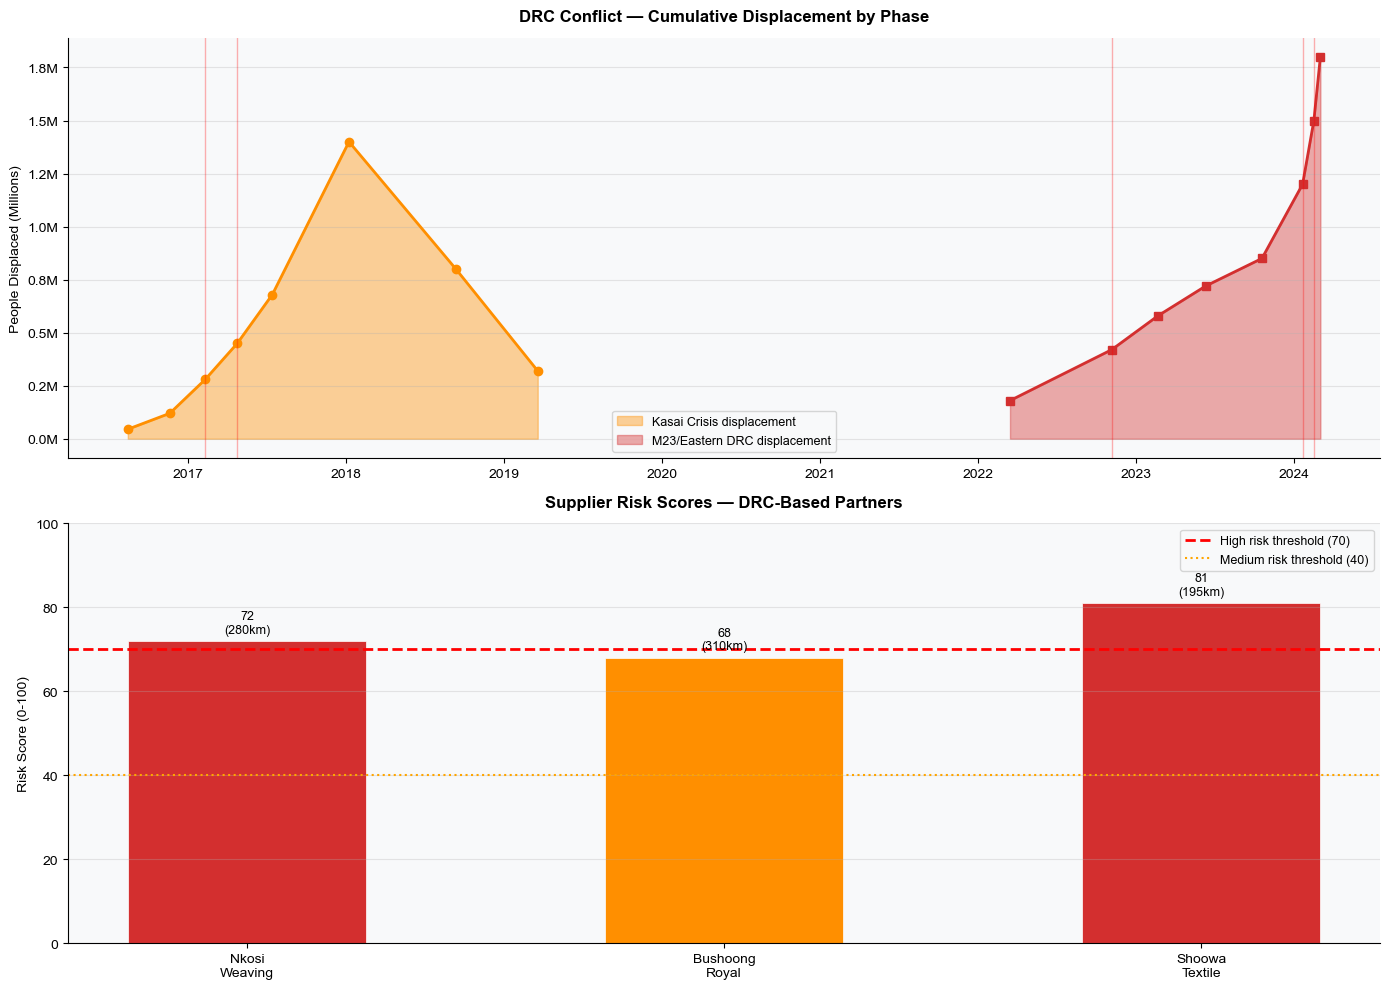

Chart 2 saved.


In [5]:
# Conflict timeline and displacement
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Chart 1: Displacement over time by conflict phase
kasai = conflict_df[conflict_df['phase'] == 'Kasai Crisis (2016-2019)']
eastern = conflict_df[conflict_df['phase'] == 'Eastern DRC/M23 (2022-present)']

axes[0].fill_between(kasai['date'], kasai['displaced_cumulative'] / 1000000,
                     alpha=0.4, color='#FF8F00', label='Kasai Crisis displacement')
axes[0].plot(kasai['date'], kasai['displaced_cumulative'] / 1000000,
             color='#FF8F00', linewidth=2, marker='o', markersize=6)

axes[0].fill_between(eastern['date'], eastern['displaced_cumulative'] / 1000000,
                     alpha=0.4, color='#D32F2F', label='M23/Eastern DRC displacement')
axes[0].plot(eastern['date'], eastern['displaced_cumulative'] / 1000000,
             color='#D32F2F', linewidth=2, marker='s', markersize=6)

axes[0].set_title('DRC Conflict — Cumulative Displacement by Phase', fontweight='bold', pad=12)
axes[0].set_ylabel('People Displaced (Millions)')
axes[0].legend(fontsize=9)
axes[0].grid(axis='y', alpha=0.3)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:.1f}M'))

for _, row in conflict_df[conflict_df['severity'] == 'CRITICAL'].iterrows():
    axes[0].axvline(row['date'], color='red', alpha=0.3, linewidth=1)

# Chart 2: Supply chain risk score by supplier
drc_suppliers = [s for s in suppliers if 'DRC' in s['region']]
names = [s['name'].split(' ')[0] + '\n' + s['name'].split(' ')[1] for s in drc_suppliers]
scores = [s['risk_score'] for s in drc_suppliers]
colors_bar = ['#D32F2F' if s >= 70 else '#FF8F00' for s in scores]

bars = axes[1].bar(names, scores, color=colors_bar, edgecolor='white', linewidth=0.5, width=0.5)
axes[1].axhline(y=70, color='red', linewidth=2, linestyle='--', label='High risk threshold (70)')
axes[1].axhline(y=40, color='orange', linewidth=1.5, linestyle=':', label='Medium risk threshold (40)')
axes[1].set_ylim(0, 100)
axes[1].set_title('Supplier Risk Scores — DRC-Based Partners', fontweight='bold', pad=12)
axes[1].set_ylabel('Risk Score (0-100)')
axes[1].legend(fontsize=9)
axes[1].grid(axis='y', alpha=0.3)

for bar, score, sup in zip(bars, scores, drc_suppliers):
    axes[1].text(bar.get_x() + bar.get_width()/2, score + 2,
                 f'{score}\n({sup["distance_to_conflict_km"]}km)', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('chart_02_conflict_proximity.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart 2 saved.')

---
## Section 3: Financial Scenario Modeling

Four scenarios based on conflict trajectory analysis. Probabilities are analyst estimates grounded in ACLED conflict data and historical DRC conflict patterns.

In [6]:
annual_2023 = revenue_df[revenue_df['Year'] == 2023]['Revenue'].sum()
drc_2023    = revenue_df[(revenue_df['Year'] == 2023) &
                          (revenue_df['Origin'].str.contains('DRC'))]['Revenue'].sum()

print('FINANCIAL SCENARIO ANALYSIS')
print('=' * 70)
print(f'Baseline 2023 Revenue:    ${annual_2023:,.0f}')
print(f'DRC-sourced Revenue:      ${drc_2023:,.0f} ({drc_2023/annual_2023:.0%})')
print()

for name, scenario in scenarios.items():
    impact = drc_2023 * scenario['drc_revenue_impact']
    new_rev = annual_2023 + impact
    prob = scenario['probability']

    risk_icon = {'LOW':'🟢','MEDIUM':'🟡','CRITICAL':'🔴'}[scenario['humanitarian_risk']]

    print(f"{'─'*70}")
    print(f"{name}")
    print(f"  Probability:        {prob:.0%}")
    print(f"  DRC Revenue Impact: {scenario['drc_revenue_impact']:.0%} of DRC revenue")
    print(f"  Annual $ Impact:    ${impact:,.0f}")
    print(f"  Projected Revenue:  ${new_rev:,.0f}")
    print(f"  Humanitarian Risk:  {risk_icon} {scenario['humanitarian_risk']}")
    print(f"  Timeline:           {scenario['timeline']}")
    print(f"  Action:             {scenario['recommended_action']}")
    print()

# Expected value
expected_impact = sum(
    drc_2023 * s['drc_revenue_impact'] * s['probability']
    for s in scenarios.values()
)
print(f"{'═'*70}")
print(f"Expected Value Impact:    ${expected_impact:,.0f}")
print(f"Expected Annual Revenue:  ${annual_2023 + expected_impact:,.0f}")
print(f"(Probability-weighted across all 4 scenarios)")

FINANCIAL SCENARIO ANALYSIS
Baseline 2023 Revenue:    $684,660
DRC-sourced Revenue:      $407,056 (59%)

──────────────────────────────────────────────────────────────────────
Base Case (Status Quo)
  Probability:        30%
  DRC Revenue Impact: 0% of DRC revenue
  Annual $ Impact:    $0
  Projected Revenue:  $684,660
  Humanitarian Risk:  🟢 LOW
  Timeline:           0-6 months
  Action:             Monitor monthly. Maintain current relationships.

──────────────────────────────────────────────────────────────────────
Scenario A — Moderate Escalation
  Probability:        45%
  DRC Revenue Impact: -40% of DRC revenue
  Annual $ Impact:    $-162,822
  Projected Revenue:  $521,838
  Humanitarian Risk:  🟡 MEDIUM
  Timeline:           3-9 months
  Action:             Activate diaspora supplier network. Increase safety stock. Reduce new DRC orders by 40%.

──────────────────────────────────────────────────────────────────────
Scenario B — Severe Escalation
  Probability:        20%
  DRC R

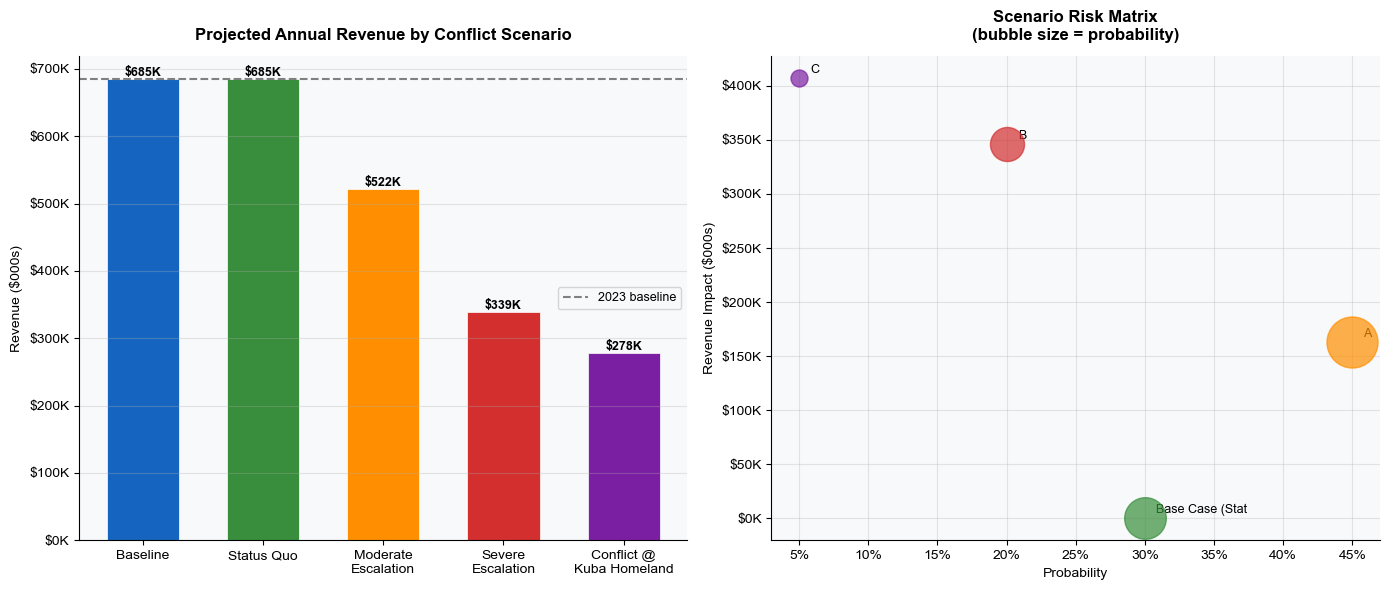

Chart 3 saved.


In [7]:
# Scenario visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Chart 1: Revenue waterfall by scenario
scenario_names  = ['Baseline', 'Status Quo', 'Moderate\nEscalation', 'Severe\nEscalation', 'Conflict @\nKuba Homeland']
scenario_revs   = [annual_2023]
for s in scenarios.values():
    scenario_revs.append(annual_2023 + drc_2023 * s['drc_revenue_impact'])

bar_colors = ['#1565C0', '#388E3C', '#FF8F00', '#D32F2F', '#7B1FA2']
bars = axes[0].bar(scenario_names, [r/1000 for r in scenario_revs],
                   color=bar_colors, edgecolor='white', linewidth=0.5, width=0.6)
axes[0].axhline(y=annual_2023/1000, color='gray', linewidth=1.5,
                linestyle='--', label='2023 baseline')
axes[0].set_title('Projected Annual Revenue by Conflict Scenario', fontweight='bold', pad=12)
axes[0].set_ylabel('Revenue ($000s)')
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:.0f}K'))
axes[0].legend(fontsize=9)
axes[0].grid(axis='y', alpha=0.3)

for bar, rev in zip(bars, scenario_revs):
    axes[0].text(bar.get_x() + bar.get_width()/2, rev/1000 + 5,
                 f'${rev/1000:.0f}K', ha='center', fontsize=9, fontweight='bold')

# Chart 2: Probability-weighted impact
prob_labels = [s.split('—')[0].strip().replace('Scenario ', '') if '—' in s else s[:15]
               for s in scenarios.keys()]
probs  = [s['probability'] for s in scenarios.values()]
impacts = [abs(drc_2023 * s['drc_revenue_impact']) / 1000 for s in scenarios.values()]

scatter_colors = ['#388E3C', '#FF8F00', '#D32F2F', '#7B1FA2']
for i, (label, prob, impact, color) in enumerate(zip(prob_labels, probs, impacts, scatter_colors)):
    axes[1].scatter(prob, impact, s=prob*3000, color=color, alpha=0.7, zorder=5)
    axes[1].annotate(label, (prob, impact),
                     textcoords='offset points', xytext=(8, 4), fontsize=9)

axes[1].set_xlabel('Probability')
axes[1].set_ylabel('Revenue Impact ($000s)')
axes[1].set_title('Scenario Risk Matrix\n(bubble size = probability)', fontweight='bold', pad=12)
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:.0%}'))
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:.0f}K'))
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('chart_03_scenarios.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart 3 saved.')

---
## Section 4: Humanitarian Impact Assessment

This section is deliberate. A supply chain analysis for a company sourcing from an artisan community in a conflict zone has an ethical dimension that belongs in the analysis — not as a footnote, but as a core input to the recommendation.

The question isn't just *what happens to our revenue* — it's *what happens to our artisan partners* under each scenario, and *what are our obligations as a buyer?*

In [8]:
print('HUMANITARIAN IMPACT FRAMEWORK')
print('=' * 70)

print('''
Context from UN OCHA and UNHCR (as of March 2024):
─────────────────────────────────────────────────────────────────────
  • 7.3 million people internally displaced in DRC — largest
    displacement crisis on the African continent
  • 358,000 newly displaced in 2024 alone (80% due to armed conflict)
  • 25 million people facing acute food insecurity (25% of population)
  • The Kasai region experienced 1.4M displaced during 2016-2018
  • Conflict specifically targets civilian infrastructure — markets,
    roads, weaving cooperatives disrupted
''')

print('Tamboli Textiles Artisan Impact by Scenario:')
print('─' * 70)

artisan_impacts = {
    'Base Case (Status Quo)': {
        'artisans_affected': 0,
        'income_loss_pct': 0,
        'displacement_risk': 'None',
        'cultural_preservation': 'Maintained',
        'our_obligation': 'Continue fair trade pricing. Communicate conflict monitoring to partners.'
    },
    'Scenario A — Moderate Escalation': {
        'artisans_affected': 18,
        'income_loss_pct': 40,
        'displacement_risk': 'Low-Medium',
        'cultural_preservation': 'At risk — income decline may accelerate artisan exit',
        'our_obligation': 'Increase per-unit payment to compensate for reduced order volume. Do not abandon partners.'
    },
    'Scenario B — Severe Escalation': {
        'artisans_affected': 54,
        'income_loss_pct': 85,
        'displacement_risk': 'High',
        'cultural_preservation': 'Seriously threatened',
        'our_obligation': 'Emergency fund. Partner with NGOs (e.g., Nest, Craftaid) for artisan support. Diaspora pivot.'
    },
    'Scenario C — Conflict Reaches Kuba Homeland': {
        'artisans_affected': 54,
        'income_loss_pct': 100,
        'displacement_risk': 'Critical — likely displacement',
        'cultural_preservation': 'Existential threat',
        'our_obligation': 'Activate emergency artisan relocation support. Document techniques. Diaspora full pivot.'
    },
}

for scenario_name, impact in artisan_impacts.items():
    print(f'\n  {scenario_name}')
    print(f'    Artisans affected:      {impact["artisans_affected"]} of 54')
    print(f'    Income loss:            {impact["income_loss_pct"]}%')
    print(f'    Displacement risk:      {impact["displacement_risk"]}')
    print(f'    Cultural preservation:  {impact["cultural_preservation"]}')
    print(f'    Our obligation:         {impact["our_obligation"]}')

HUMANITARIAN IMPACT FRAMEWORK

Context from UN OCHA and UNHCR (as of March 2024):
─────────────────────────────────────────────────────────────────────
  • 7.3 million people internally displaced in DRC — largest
    displacement crisis on the African continent
  • 358,000 newly displaced in 2024 alone (80% due to armed conflict)
  • 25 million people facing acute food insecurity (25% of population)
  • The Kasai region experienced 1.4M displaced during 2016-2018
  • Conflict specifically targets civilian infrastructure — markets,
    roads, weaving cooperatives disrupted

Tamboli Textiles Artisan Impact by Scenario:
──────────────────────────────────────────────────────────────────────

  Base Case (Status Quo)
    Artisans affected:      0 of 54
    Income loss:            0%
    Displacement risk:      None
    Cultural preservation:  Maintained
    Our obligation:         Continue fair trade pricing. Communicate conflict monitoring to partners.

  Scenario A — Moderate Escalation
 

---
## Section 5: Diaspora Supplier Network Analysis

The strategic hedge: Kuba diaspora artisans in Europe and the US can produce authentic cloth using traditional techniques. They offer lower geopolitical risk and faster lead times, at a cost premium.

In [9]:
print('DIASPORA SUPPLIER NETWORK — CAPACITY ANALYSIS')
print('=' * 70)

total_diaspora_capacity = sum(d['annual_capacity_units'] for d in diaspora)
drc_capacity = sum(s['annual_units'] for s in suppliers if 'DRC' in s['region'])

print(f'Current DRC capacity:      {drc_capacity} units/year')
print(f'Diaspora total capacity:   {total_diaspora_capacity} units/year ({total_diaspora_capacity/drc_capacity:.0%} of DRC volume)')
print()

print(f'{"Supplier":<35} {"Location":<20} {"Units/yr":>8} {"Premium":>9} {"Lead Time":>10} {"Status"}')
print('-' * 95)
for d in diaspora:
    print(f"{d['name']:<35} {d['location']:<20} {d['annual_capacity_units']:>8} "
          f"+{d['cost_premium_pct']:>6}%  {d['lead_time_days']:>7}d  {d['status']}")

print()
# Cost analysis
kuba_cost_base = 45  # cost per unit from DRC
avg_premium = np.mean([d['cost_premium_pct'] for d in diaspora]) / 100
kuba_cost_diaspora = kuba_cost_base * (1 + avg_premium)
retail_price = 195

print(f'Cost comparison:')
print(f'  DRC sourcing cost:       ${kuba_cost_base:.0f}/unit   Margin: {(retail_price-kuba_cost_base)/retail_price:.0%}')
print(f'  Diaspora avg cost:       ${kuba_cost_diaspora:.0f}/unit   Margin: {(retail_price-kuba_cost_diaspora)/retail_price:.0%}')
print(f'  Margin reduction:        -{(kuba_cost_diaspora-kuba_cost_base)/retail_price:.0%} per unit')
print()
print('  At full diaspora pivot (415 units/year):')
annual_margin_loss = (kuba_cost_diaspora - kuba_cost_base) * total_diaspora_capacity
print(f'  Additional annual cost:  ${annual_margin_loss:,.0f}')
print(f'  vs. Scenario B revenue loss: ${abs(scenarios["Scenario B — Severe Escalation"]["annual_revenue_impact"]):,.0f}')
print(f'  Net advantage of diaspora pivot: ${abs(scenarios["Scenario B — Severe Escalation"]["annual_revenue_impact"]) - annual_margin_loss:,.0f}')

DIASPORA SUPPLIER NETWORK — CAPACITY ANALYSIS
Current DRC capacity:      660 units/year
Diaspora total capacity:   415 units/year (63% of DRC volume)

Supplier                            Location             Units/yr   Premium  Lead Time Status
-----------------------------------------------------------------------------------------------
Kuba Arts Collective — Brussels     Brussels, Belgium         120 +    35%       21d  Active partner
Raffia & Root Studio — Brooklyn NY  Brooklyn, NY, USA          55 +    55%       14d  Exploratory
Congo Textile Arts — Paris          Paris, France             160 +    40%       18d  Active partner
Kasai Weavers Network — London      London, UK                 80 +    45%       16d  Exploratory

Cost comparison:
  DRC sourcing cost:       $45/unit   Margin: 77%
  Diaspora avg cost:       $65/unit   Margin: 67%
  Margin reduction:        -10% per unit

  At full diaspora pivot (415 units/year):
  Additional annual cost:  $8,170
  vs. Scenario B revenue

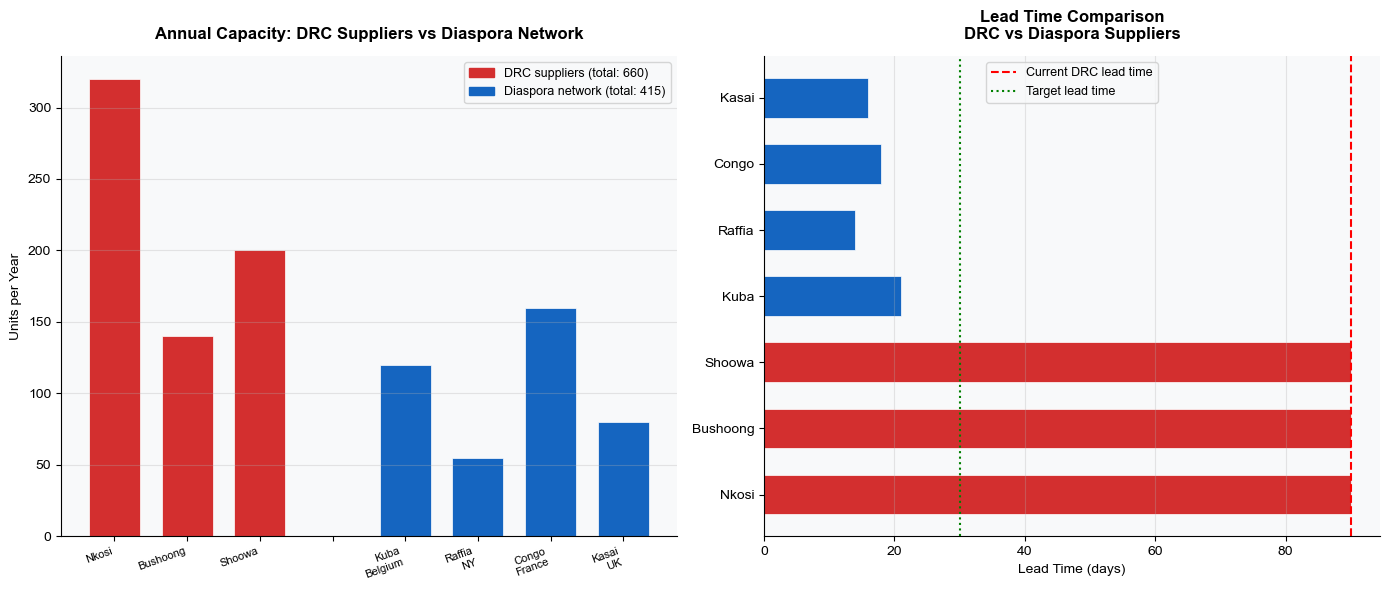

Chart 4 saved.


In [10]:
# Diaspora capacity visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Chart 1: Capacity comparison
supplier_names = [s['name'].split(' ')[0] for s in suppliers if 'DRC' in s['region']]
supplier_caps  = [s['annual_units'] for s in suppliers if 'DRC' in s['region']]
diaspora_names = [d['name'].split(' ')[0] + '\n' + d['location'].split(',')[1].strip()
                  for d in diaspora]
diaspora_caps  = [d['annual_capacity_units'] for d in diaspora]

all_names  = supplier_names + [''] + diaspora_names
all_caps   = supplier_caps + [0] + diaspora_caps
all_colors = ['#D32F2F'] * 3 + ['white'] + ['#1565C0'] * 4

bars = axes[0].bar(range(len(all_names)), all_caps,
                   color=all_colors, edgecolor='white', linewidth=0.5, width=0.7)
axes[0].set_xticks(range(len(all_names)))
axes[0].set_xticklabels(all_names, fontsize=8, rotation=20, ha='right')
axes[0].set_title('Annual Capacity: DRC Suppliers vs Diaspora Network',
                  fontweight='bold', pad=12)
axes[0].set_ylabel('Units per Year')
axes[0].grid(axis='y', alpha=0.3)

red_patch   = mpatches.Patch(color='#D32F2F', label=f'DRC suppliers (total: {drc_capacity})')
blue_patch  = mpatches.Patch(color='#1565C0', label=f'Diaspora network (total: {total_diaspora_capacity})')
axes[0].legend(handles=[red_patch, blue_patch], fontsize=9)

# Chart 2: Lead time comparison
all_suppliers_lead = (
    [(s['name'].split(' ')[0], 90, '#D32F2F') for s in suppliers if 'DRC' in s['region']] +
    [(d['name'].split(' ')[0], d['lead_time_days'], '#1565C0') for d in diaspora]
)
names_lt, days_lt, colors_lt = zip(*all_suppliers_lead)
axes[1].barh(names_lt, days_lt, color=colors_lt, edgecolor='white', linewidth=0.5, height=0.6)
axes[1].axvline(x=90, color='red', linewidth=1.5, linestyle='--', label='Current DRC lead time')
axes[1].axvline(x=30, color='green', linewidth=1.5, linestyle=':', label='Target lead time')
axes[1].set_title('Lead Time Comparison\nDRC vs Diaspora Suppliers', fontweight='bold', pad=12)
axes[1].set_xlabel('Lead Time (days)')
axes[1].legend(fontsize=9)
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('chart_04_diaspora.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart 4 saved.')

---
## Section 6: Recommendation & Ethical Framework

In [11]:
annual_2023 = revenue_df[revenue_df['Year'] == 2023]['Revenue'].sum()
drc_2023    = revenue_df[(revenue_df['Year'] == 2023) &
                          (revenue_df['Origin'].str.contains('DRC'))]['Revenue'].sum()

print('=' * 70)
print('STRATEGIC RECOMMENDATION — TAMBOLI TEXTILES CO.')
print('DRC Supply Chain Risk Assessment | March 2024')
print('=' * 70)
print()
print('RECOMMENDATION: PAUSE + PIVOT (Scenario A preparation)')
print()
print('Rationale:')
print('  The current conflict is geographically 280-310km from our primary')
print('  suppliers. This provides a buffer — but the 2016-2018 Kasai crisis')
print('  demonstrates that regional conflict can reach the Kuba homeland')
print('  within months. Waiting until disruption occurs means 90+ days of')
print('  zero inventory before a diaspora pivot could take effect.')
print()
print('IMMEDIATE ACTIONS (0-30 days):')
print('  1. Contact all DRC suppliers — welfare check + contingency planning')
print('  2. Place final Scenario A safety stock order (3-month buffer)')
print('  3. Execute letters of intent with Brussels and Paris diaspora suppliers')
print('  4. Establish $15,000 Artisan Emergency Fund (reserves, not operating budget)')
print()
print('30-60 DAY ACTIONS:')
print('  5. Begin diaspora onboarding — quality validation, pricing, lead time testing')
print('  6. Establish conflict monitoring cadence (ACLED weekly alerts for Kasai region)')
print('  7. Develop "conflict-transparent" product narrative for retail partners')
print()
print('TRIGGER POINTS FOR ESCALATION:')
print('  → Scenario A: Any armed group activity within 150km of Kasai-Central')
print('  → Scenario B: Confirmed fighting in Kasai province')
print('  → Scenario C: Any attack on or near known weaving cooperative locations')
print()
print('ETHICAL FRAMEWORK:')
print('  We do NOT recommend a PMC deployment or any armed intervention.')
print('  We DO recommend:')
print('  • Fair trade pricing maintained even if order volumes decline')
print('  • Artisan emergency fund as a standing obligation, not a gesture')
print('  • Diaspora pivot framed as EXPANSION, not replacement — maintaining')
print('    DRC relationships alongside diaspora development')
print('  • Transparency with retail partners about sourcing situation')
print('  • Advocacy: support organizations documenting Kuba weaving techniques')
print('    to preserve knowledge even if production is disrupted')
print()
print('FINANCIAL SUMMARY:')
print(f'  2023 baseline revenue:          ${annual_2023:,.0f}')
print(f'  Expected value under scenarios: ${annual_2023 + sum(drc_2023*s["drc_revenue_impact"]*s["probability"] for s in scenarios.values()):,.0f}')
print(f'  Cost of recommended actions:    ~$28,000 (safety stock + fund + diaspora onboarding)')
print(f'  Cost of doing nothing (Scenario B): ${abs(scenarios["Scenario B — Severe Escalation"]["annual_revenue_impact"]):,.0f}')
print(f'  Risk-adjusted ROI of action:    {abs(scenarios["Scenario B — Severe Escalation"]["annual_revenue_impact"]) / 28000:.1f}x')
print()
print('This is a decision that involves both financial prudence and ethical')
print('responsibility. They point in the same direction.')

STRATEGIC RECOMMENDATION — TAMBOLI TEXTILES CO.
DRC Supply Chain Risk Assessment | March 2024

RECOMMENDATION: PAUSE + PIVOT (Scenario A preparation)

Rationale:
  The current conflict is geographically 280-310km from our primary
  suppliers. This provides a buffer — but the 2016-2018 Kasai crisis
  demonstrates that regional conflict can reach the Kuba homeland
  within months. Waiting until disruption occurs means 90+ days of
  zero inventory before a diaspora pivot could take effect.

IMMEDIATE ACTIONS (0-30 days):
  1. Contact all DRC suppliers — welfare check + contingency planning
  2. Place final Scenario A safety stock order (3-month buffer)
  3. Execute letters of intent with Brussels and Paris diaspora suppliers
  4. Establish $15,000 Artisan Emergency Fund (reserves, not operating budget)

30-60 DAY ACTIONS:
  5. Begin diaspora onboarding — quality validation, pricing, lead time testing
  6. Establish conflict monitoring cadence (ACLED weekly alerts for Kasai region)
  7. De